# Сверточные нейронные сети (ноутбук)

В этом ноутбуке мы углубимся в изучение сверточных нейронных сетей (Convolutional Neural Networks, CNNs) — мощного инструмента для работы с изображениями. Мы поймем, почему они так эффективны по сравнению с полносвязными сетями, разберем основные строительные блоки CNN, такие как свертки и пулинг, и увидим, как их применять в PyTorch.

**Цель урока:** Научиться решать задачу классификации изображений, используя сверточные нейронные сети. Мы разберем, как CNNs решают проблемы полносвязных сетей при работе с визуальными данными, изучим их архитектурные особенности и основные гиперпараметры, а также применим полученные знания на практике, обучив модель для классификации рукописных цифр MNIST.

На предыдущей лекции мы научились собирать нейронные сети как конструктор, используя PyTorch, и познакомились с базовыми принципами их обучения. Однако, при работе с изображениями, полносвязные сети сталкиваются с рядом существенных недостатков:

1.  **Потеря пространственной информации:** Полносвязные сети требуют "разворачивания" (flattening) изображения в одномерный вектор. Это приводит к потере информации о взаимном расположении пикселей, что критично для понимания содержимого изображения.
2.  **Огромное количество параметров:** Даже для небольших изображений (например, 28x28 пикселей), полносвязный слой, принимающий на вход `28 * 28 = 784` пикселя и имеющий, скажем, 1000 нейронов, будет иметь `784 * 1000 = 784,000` параметров. С увеличением размера изображения и количества слоев число параметров быстро становится астрономическим, что ведет к переобучению и медленному обучению.
3.  **Отсутствие инвариантности к сдвигам и поворотам:** Полносвязные сети не могут "понимать", что один и тот же объект, слегка сдвинутый или повернутый на изображении, по-прежнему является тем же объектом. Они вынуждены заново "учить" каждый вариант расположения объекта.

Сверточные нейронные сети были разработаны специально для обхода этих проблем, используя принципы, вдохновленные зрительной корой живых организмов. Они способны эффективно извлекать пространственные признаки и значительно сокращать количество параметров.

In [1]:
import warnings # Модуль для управления предупреждениями. Мы будем его использовать, чтобы игнорировать некоторые предупреждения, которые могут появляться во время выполнения кода.

import matplotlib.pyplot as plt # Библиотека для построения графиков и визуализации данных. Очень полезна для отображения изображений и результатов обучения.
import numpy as np # Библиотека для работы с многомерными массивами и математическими операциями. Часто используется для предобработки данных.
import torch # Основная библиотека PyTorch, предоставляющая тензоры и широкий набор функций для глубокого обучения.
import torch.nn as nn # Модуль PyTorch, содержащий классы для построения нейронных сетей (слои, функции активации и т.д.).
import torchvision.transforms as T # Модуль TorchVision, предоставляющий стандартные преобразования для изображений.
from IPython.display import clear_output # Функция для очистки вывода ячейки в Jupyter Notebook, чтобы графики не накладывались друг на друга.
from PIL import Image # Библиотека Pillow, используемая для открытия, обработки и сохранения изображений.
from matplotlib import cm # Модуль для работы с цветовыми картами в Matplotlib, полезен для визуализации каналов изображений.
from time import perf_counter # Функция для измерения времени выполнения операций.
from torch.utils.data import DataLoader # Класс для создания итераторов по датасетам, облегчающий работу с батчами данных.
from torchvision.datasets import MNIST # Класс для загрузки датасета MNIST из TorchVision.
from tqdm import tqdm # Библиотека для создания прогресс-баров, что очень удобно для отслеживания хода обучения.

warnings.filterwarnings('ignore') # Игнорируем все предупреждения, чтобы не загромождать вывод.

plt.rc('font', size=30) # Устанавливаем глобальный размер шрифта для всех графиков Matplotlib, чтобы текст был хорошо читаем.

## Загрузка и представление изображений

Прежде чем перейти к сверточным сетям, давайте вспомним, как изображения представляются в компьютере и, в частности, в контексте глубокого обучения.

В большинстве случаев изображения представлены в одном из двух цветовых пространств:
*   **Grayscale (оттенки серого):** Изображение имеет один канал, где каждый пиксель представлен значением интенсивности света, обычно от 0 (черный) до 255 (белый).
*   **RGB (Red, Green, Blue):** Изображение имеет три канала — красный, зеленый и синий. Каждый канал представляет интенсивность соответствующего цвета для каждого пикселя, также обычно от 0 до 255. Комбинируя эти три канала, можно получить миллионы различных цветов.

В глубинном обучении изображения обычно представляются как многомерные тензоры. Размеры этих тензоров могут варьироваться в зависимости от используемой библиотеки, но чаще всего это:
*   **NumPy и Matplotlib:** `(высота, ширина, каналы)` или `(H, W, C)`.
*   **PyTorch (после преобразования `ToTensor`):** `(каналы, высота, ширина)` или `(C, H, W)`.

Также, нейронные сети обычно обрабатывают изображения батчами (пакетами). Поэтому к этим размерностям часто добавляется еще одна: `(размер_батча, каналы, высота, ширина)` или `(N, C, H, W)`, где `N` - количество изображений в батче.

Давайте загрузим изображение и посмотрим на его свойства и представление.

In [2]:
# Загружаем изображение Питера Гриффина из интернета.
# `wget` - это утилита командной строки для скачивания файлов.
# `-O peter.jpg` указывает, что скачанный файл должен быть сохранен как 'peter.jpg'.
!curl -o peter.jpg "https://static.independent.co.uk/2021/10/29/14/newFile-8.jpg?width=1200"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  109k  100  109k    0     0   234k      0 --:--:-- --:--:-- --:--:--  235k


## Чтение изображения с помощью Pillow

Библиотека `Pillow` (PIL fork) является стандартом де-факто для обработки изображений в Python. Она позволяет легко открывать, манипулировать и сохранять изображения.

In [3]:
# Открываем скачанное изображение с помощью Pillow.
# Объект 'img' теперь содержит информацию об изображении.
img = Image.open('peter.jpg')

Мы можем получить различные метаданные об изображении с помощью атрибутов объекта `Image`:
*   `img.format`: Формат файла изображения (например, JPEG, PNG).
*   `img.size`: Размеры изображения в пикселях (ширина, высота).
*   `img.mode`: Цветовое пространство изображения (например, RGB, L для Grayscale).

In [4]:
# Выводим формат изображения.
img.format

'JPEG'

In [5]:
# Выводим размеры изображения (ширина, высота).
img.size

(1200, 899)

In [6]:
# Выводим цветовой режим изображения. 'RGB' означает, что у изображения 3 канала: Красный, Зеленый, Синий.
img.mode

'RGB'

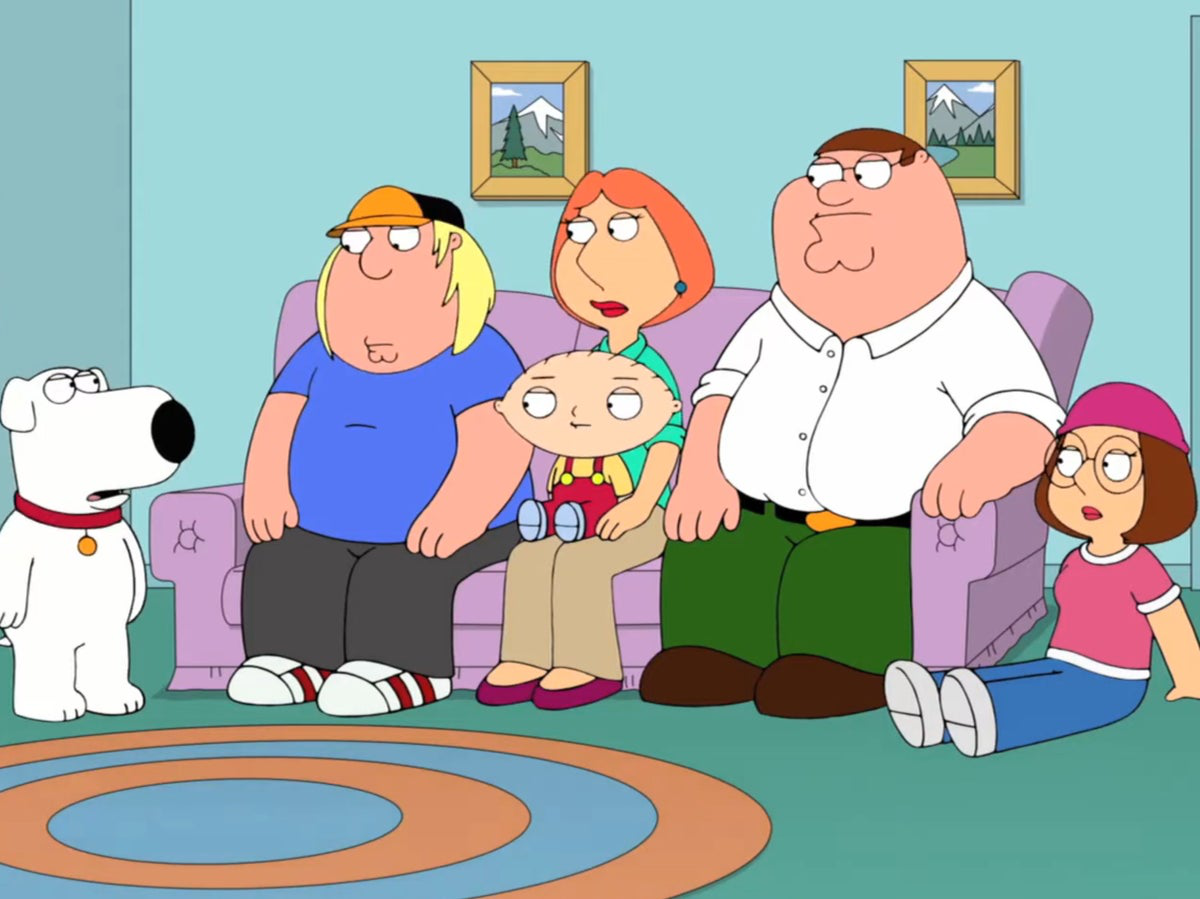

In [7]:
# Просто вывод объекта `img` в Jupyter Notebook отображает само изображение.
img

## Матричное представление изображения

Чтобы нейронная сеть могла работать с изображением, его необходимо преобразовать в числовую матрицу (или тензор). `NumPy` отлично подходит для этого.
Когда мы преобразуем `PIL.Image` в `NumPy` массив, порядок осей будет `(высота, ширина, каналы)`.

In [8]:
# Преобразуем объект Pillow Image в NumPy массив.
# Каждый пиксель будет представлен числом (или набором чисел для RGB),
# а все изображение - многомерным массивом.
img_matrix = np.array(img)

Размеры полученного NumPy массива подтверждают порядок `(высота, ширина, каналы)`. В нашем случае это `899` пикселей по высоте, `1200` по ширине и `3` канала (для RGB).

In [9]:
# Выводим форму (shape) полученного NumPy массива.
img_matrix.shape

(899, 1200, 3)

Теперь, когда изображение представлено в виде числовой матрицы, мы можем использовать `matplotlib` для его визуализации.

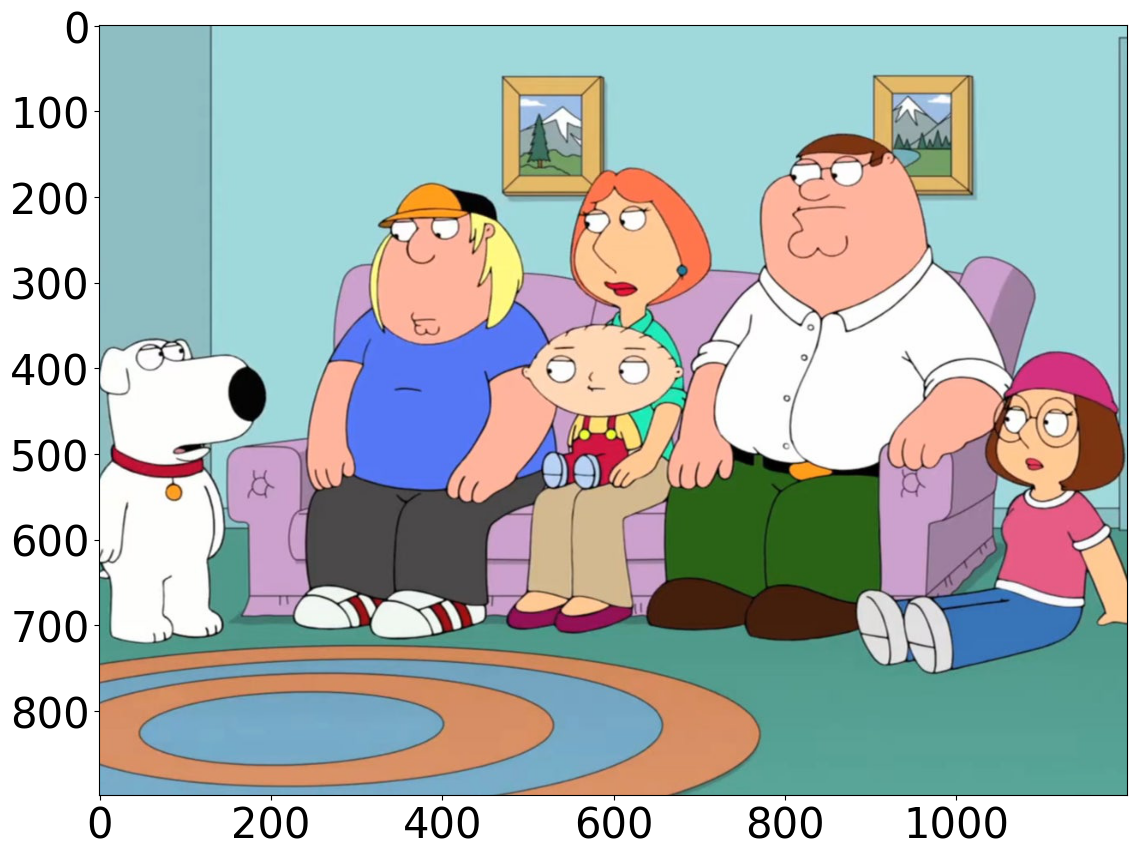

In [10]:
# Создаем новое окно для графика с заданным размером.
plt.figure(figsize=(20, 10))

# Отображаем изображение из NumPy массива. Matplotlib ожидает формат (высота, ширина, каналы) для RGB изображений.
plt.imshow(img_matrix)

# Показываем график.
plt.show()

Для лучшего понимания того, как работает RGB-изображение, давайте визуализируем каждый из трех каналов по отдельности.
Каждый канал (красный, зеленый, синий) представляет собой 2D-матрицу, где значения пикселей показывают интенсивность этого конкретного цвета.
Например, для красного канала:
*   Высокие значения (близкие к 255) означают, что в этой области изображения присутствует много красного цвета.
*   Низкие значения (близкие к 0) означают отсутствие красного.

Пример:
*   Белый цвет имеет высокую интенсивность во всех трех каналах.
*   Черный цвет имеет низкую интенсивность во всех трех каналах.
*   Розовый цвет имеет высокую интенсивность красного и синего, но низкую зеленого.

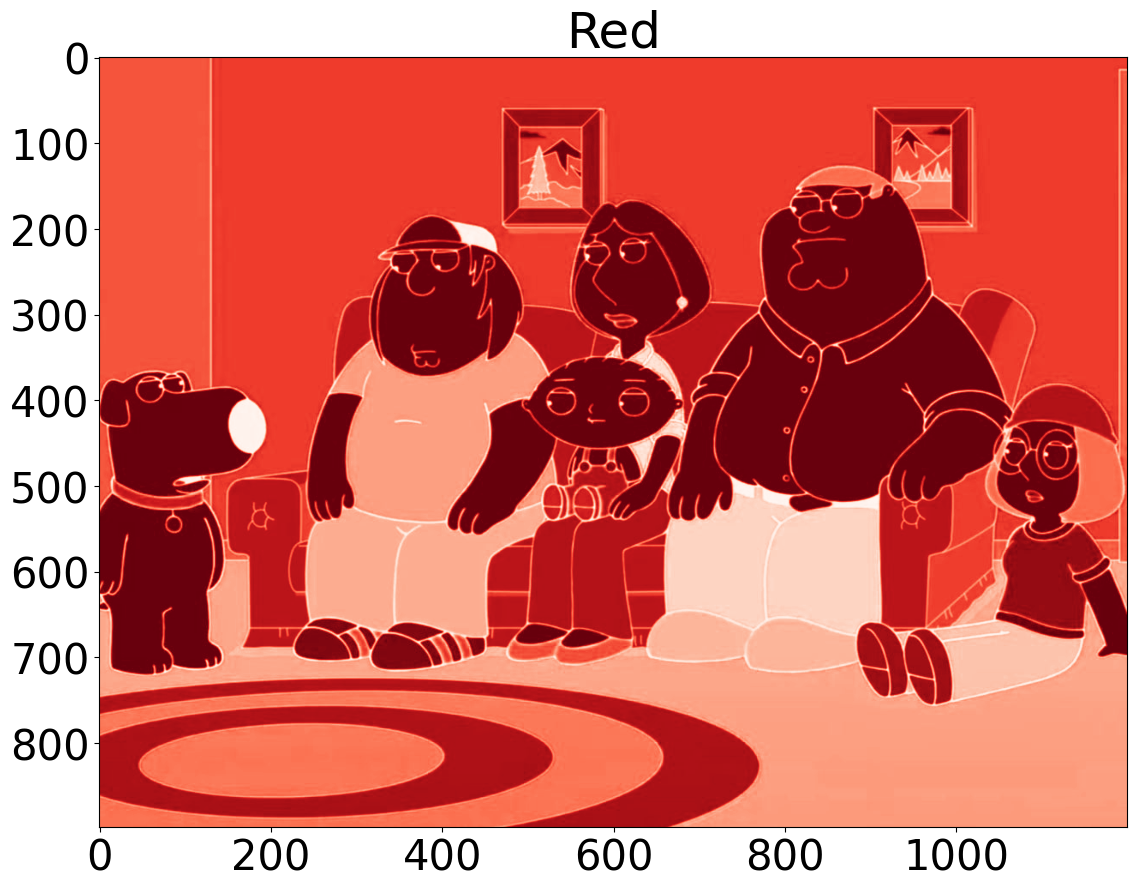

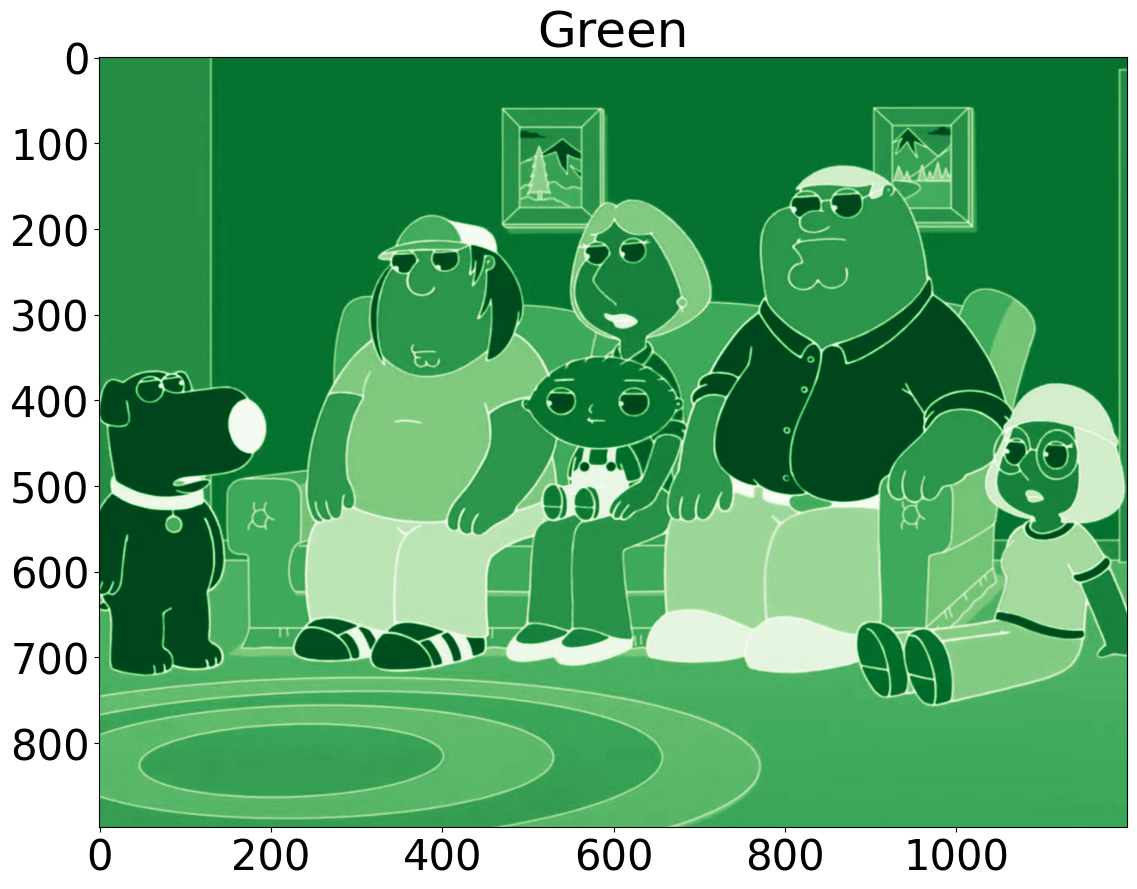

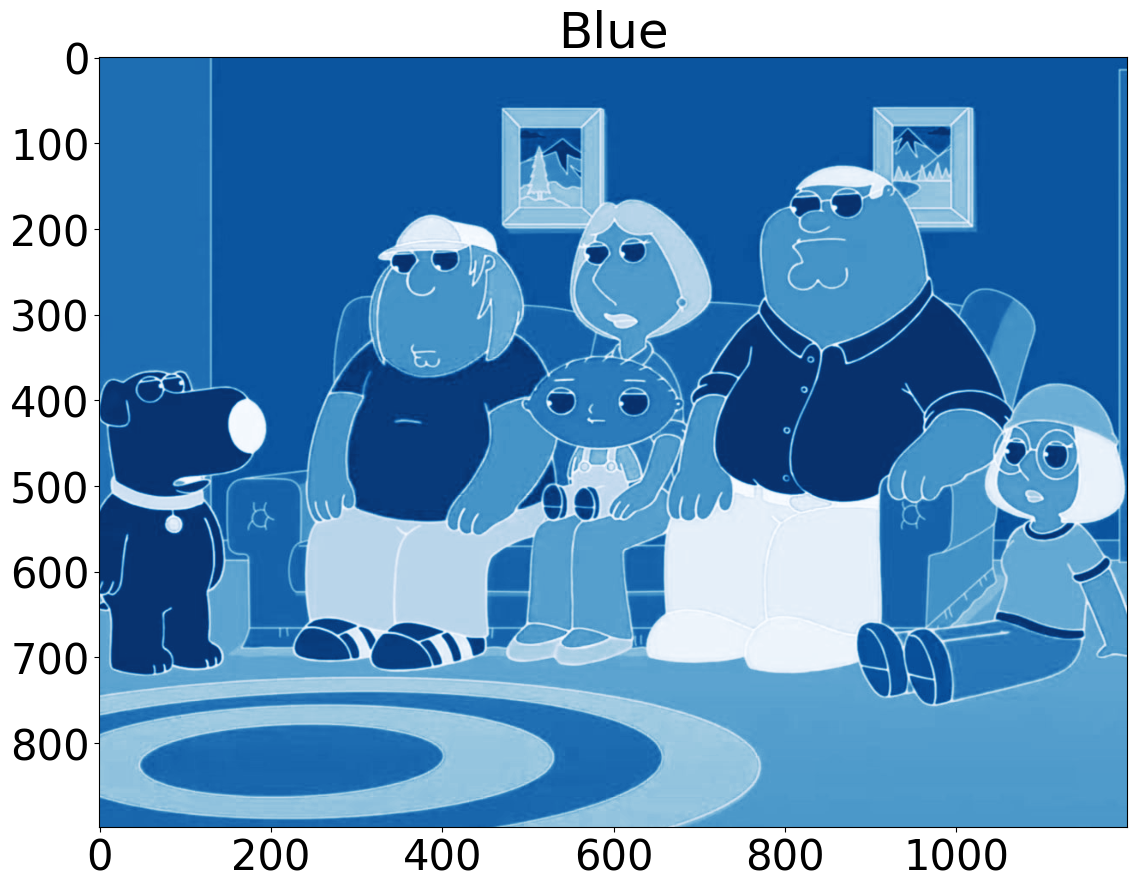

In [11]:
# Итерируемся по каждому каналу изображения (0: красный, 1: зеленый, 2: синий).
for i, (cmap, color) in enumerate(
    zip(
        [cm.Reds, cm.Greens, cm.Blues], # Цветовые карты для каждого канала (красный, зеленый, синий).
        ['Red', 'Green', 'Blue']       # Названия каналов для заголовков графиков.
    )
):
    plt.figure(figsize=(20, 10)) # Создаем новое окно для графика.
    
    # Извлекаем i-й канал из img_matrix. `:` означает "все элементы" по высоте и ширине.
    # `cmap=cmap` применяет соответствующую цветовую карту для монохромного изображения.
    plt.imshow(img_matrix[:, :, i], cmap=cmap) 
    plt.title(color) # Устанавливаем заголовок графика.
    plt.show() # Показываем график.

Пиксели в 8-битном изображении (наиболее распространенный формат) обычно имеют значения от 0 до 255.
*   `0` обычно соответствует минимальной интенсивности (например, отсутствие цвета).
*   `255` соответствует максимальной интенсивности (например, полная насыщенность цвета).

Тип данных `uint8` (беззнаковое 8-битное целое число) идеально подходит для хранения таких значений, так как он может представлять числа от 0 до 255.

In [12]:
# Выводим минимальное и максимальное значения пикселей в первом канале (красном).
# Это подтверждает, что значения находятся в диапазоне от 0 до 255.
img_matrix[:, :, 0].min(), img_matrix[:, :, 0].max()

(0, 255)

In [13]:
# Выводим первые элементы NumPy массива.
# Мы видим числовое представление пикселей. Каждая строка представляет собой строку изображения,
# а внутри каждой строки - кортежи (R, G, B) для каждого пикселя.
img_matrix

array([[[142, 190, 194],
        [142, 190, 194],
        [142, 190, 194],
        ...,
        [157, 218, 219],
        [157, 218, 219],
        [157, 218, 219]],

       [[142, 190, 194],
        [142, 190, 194],
        [142, 190, 194],
        ...,
        [157, 218, 219],
        [157, 218, 219],
        [157, 218, 219]],

       [[142, 190, 194],
        [142, 190, 194],
        [142, 190, 194],
        ...,
        [158, 218, 219],
        [158, 218, 219],
        [158, 218, 219]],

       ...,

       [[121, 172, 201],
        [121, 172, 201],
        [121, 172, 201],
        ...,
        [ 91, 165, 152],
        [ 91, 165, 152],
        [ 91, 165, 152]],

       [[121, 172, 201],
        [121, 172, 201],
        [121, 172, 201],
        ...,
        [ 91, 165, 152],
        [ 91, 165, 152],
        [ 91, 165, 152]],

       [[121, 172, 201],
        [121, 172, 201],
        [121, 172, 201],
        ...,
        [ 91, 165, 152],
        [ 91, 165, 152],
        [ 91, 165, 152]]

## Свертка (Convolution)

**Свертка** — это ключевая операция в сверточных нейронных сетях. Она позволяет извлекать локальные признаки (паттерны) из изображений, такие как края, текстуры или углы.

**Как работает свертка:**
1.  **Фильтр (Ядро свертки/Kernel):** Это небольшая матрица (например, 3x3 или 5x5), которая содержит обучаемые веса. Этот фильтр скользит по всему входному изображению.
2.  **Поэлементное умножение:** На каждом шаге фильтр накладывается на небольшой участок изображения того же размера, что и фильтр. Затем происходит поэлементное умножение значений пикселей изображения на соответствующие веса фильтра.
3.  **Суммирование:** Все результаты поэлементного умножения суммируются в одно значение.
4.  **Выходная карта признаков (Feature Map):** Полученное суммарное значение записывается в соответствующую позицию выходной матрицы. Фильтр затем сдвигается на определенное количество шагов (страйд), и процесс повторяется до тех пор, пока он не пройдет по всему изображению.

**Важные свойства свертки:**
*   **Local Connectivity (Локальная связность):** Каждый нейрон в выходном слое связан только с небольшой локальной областью входного изображения (размером с фильтр). Это значительно уменьшает количество параметров по сравнению с полносвязными слоями.
*   **Shared Weights (Общие веса):** Один и тот же фильтр (с одними и теми же весами) применяется ко всему изображению. Это означает, что если определенный паттерн (например, вертикальная линия) обнаруживается в одном месте изображения, тот же фильтр сможет обнаружить его и в другом месте. Это обеспечивает **инвариантность к сдвигам** (shift invariance) — способность модели распознавать объект независимо от его положения на изображении. Это также еще сильнее уменьшает количество параметров.
*   **Pattern Detection (Обнаружение паттернов):** Значения в ядре свертки (фильтре) обучаются таким образом, чтобы он "откликался" (давал большое суммарное значение) при обнаружении определенного паттерна во входных данных. Чем сильнее паттерн присутствует, тем больше будет отклик.

В `PyTorch` сверточный слой представлен модулем `nn.Conv2d`.

### Параметры `nn.Conv2d`:

*   `in_channels` (int): **Количество входных каналов.** Это число каналов в тензоре, подаваемом на вход текущего сверточного слоя. Например, для цветного RGB изображения это `3`, для черно-белого — `1`. Если это не первый слой в сети, то `in_channels` будет равно `out_channels` предыдущего слоя.
*   `out_channels` (int): **Количество выходных каналов (или количество фильтров).** Это число различных фильтров, которые будут применены к входному изображению. Каждый фильтр будет извлекать свой уникальный паттерн, создавая одну выходную карту признаков. Таким образом, `out_channels` определяет "глубину" выходной карты признаков.
*   `kernel_size` (int or tuple): **Размер ядра свертки.** Определяет ширину и высоту фильтра. Может быть задан одним целым числом (например, `3` для ядра 3x3) или кортежем `(height, width)` (например, `(3, 5)` для ядра 3x5).
*   `stride` (int or tuple, optional): **Шаг (сдвиг) ядра свертки.** Определяет, насколько фильтр будет сдвигаться по изображению после каждой операции свертки. По умолчанию `1` (фильтр сдвигается на один пиксель). Если `stride=2`, фильтр сдвигается на два пикселя, что приводит к уменьшению размера выходной карты признаков и увеличению поля восприятия следующих слоев.
*   `padding` (int, tuple or str, optional): **Размер паддинга (дополнения по краям).** Добавление нулевых или других значений по краям входного изображения.
    *   **Зачем нужен паддинг?**
        1.  **Сохранение размера:** Без паддинга размер выходного изображения уменьшается с каждым сверточным слоем. Паддинг позволяет контролировать размер выходной карты признаков, часто сохраняя его таким же, как и входной (`"same"` padding).
        2.  **Обработка краевой информации:** Пиксели по краям изображения обрабатываются меньше раз, чем центральные пиксели. Паддинг гарантирует, что краевая информация также учитывается, предотвращая потерю важных признаков, которые могут находиться на границах.
    *   По умолчанию `0` (нет паддинга, так называемый `"valid"` mode, где выходной размер уменьшается).
    *   Для ядра `KxK` и `stride=1`, чтобы сохранить размер, нужно установить `padding = (K-1)/2`. Например, для `kernel_size=3`, `padding=1`.
*   `padding_mode` (string, optional): **Режим паддинга.** Определяет, как заполняются добавленные пиксели. По умолчанию `'zeros'` (заполнение нулями). Другие варианты:
    *   `'reflect'` (отражение): Заполняет края отраженными значениями пикселей.
    *   `'replicate'` (копирование): Заполняет края повторяющимися значениями ближайших пикселей.
    *   Хотя эти режимы могут быть полезны, они также могут привести к "переобучению под край", так как фильтр может научиться детектировать характерные паттерны, создаваемые паддингом. На практике `zeros` padding наиболее распространен.
*   `dilation` (int or tuple, optional): **Дилейшн (расширенная свертка).** Определяет шаг между элементами внутри самого ядра свертки. Позволяет ядру охватывать большую область входного изображения (увеличивать "поле восприятия") без увеличения количества параметров или уменьшения разрешения выходной карты признаков. По умолчанию `1`. `dilation=2` означает, что между элементами ядра вставляется один "пропуск", как будто ядро "расширяется".
*   `bias` (bool, optional): **Добавлять ли обучаемый сдвиг (bias).** По умолчанию `True`. Сдвиг добавляется к каждому элементу выходной карты признаков после операции свертки. Это позволяет нейрону сдвигать активацию в произвольном направлении, увеличивая гибкость модели.

Давайте создадим простой сверточный слой и посмотрим, как он обрабатывает наше изображение.

In [14]:
# Создаем сверточный слой.
# in_channels=3: На вход слоя приходит цветное RGB изображение (3 канала).
# out_channels=10: Слой будет использовать 10 различных фильтров, каждый из которых будет искать свой паттерн
#                 и генерировать свою выходную карту признаков. Таким образом, на выходе будет 10 каналов.
# kernel_size=3: Размер ядра свертки 3x3 пикселя.
conv1 = nn.Conv2d(
    in_channels=3,
    out_channels=10,
    kernel_size=3
)

Для того чтобы PyTorch-слои могли обрабатывать изображение, его нужно преобразовать в PyTorch-тензор.
`torchvision.transforms.ToTensor()` выполняет несколько важных действий:
1.  Конвертирует `PIL.Image` (или NumPy массив) в `torch.FloatTensor`.
2.  Нормализует значения пикселей из диапазона `[0, 255]` в `[0.0, 1.0]`.
3.  **Меняет порядок осей!** Из `(высота, ширина, каналы)` (`HWC`) в `(каналы, высота, ширина)` (`CHW`).

Кроме того, PyTorch слои (как `nn.Conv2d`) ожидают вход в виде батча (пакета) изображений, даже если это всего одно изображение. Формат входного тензора должен быть `(размер_батча, каналы, высота, ширина)` (`NCHW`).
Мы используем `.unsqueeze(0)` для добавления этой "батчевой" размерности.

In [15]:
# Преобразуем изображение PIL в PyTorch тензор и добавляем размерность батча.
# T.ToTensor()(img): конвертирует PIL.Image в FloatTensor, меняет оси на CHW.
# .unsqueeze(0): добавляет размерность батча (batch_size=1), превращая (C, H, W) в (N, C, H, W).
img_tensor = T.ToTensor()(img).unsqueeze(0)

Теперь тензор имеет ожидаемый PyTorch формат: `1` (размер батча) `x 3` (каналы) `x 899` (высота) `x 1200` (ширина).

In [16]:
# Выводим форму полученного тензора.
img_tensor.shape

torch.Size([1, 3, 899, 1200])

Применяем сверточный слой к тензору изображения.

In [17]:
# Выполняем прямой проход (forward pass) через сверточный слой.
output = conv1(img_tensor)

Посмотрите на форму выходного тензора:
*   Размер батча остался `1`.
*   Количество каналов стало `10` (как мы задали `out_channels`).
*   Высота и ширина изображения **уменьшились**. Почему?
    Поскольку мы не задали `padding`, `nn.Conv2d` по умолчанию использует `padding=0` (режим "valid"). Для `kernel_size=3`:
    *   `Высота_выхода = Высота_входа - kernel_size + 1 = 899 - 3 + 1 = 897`
    *   `Ширина_выхода = Ширина_входа - kernel_size + 1 = 1200 - 3 + 1 = 1198`

Таким образом, каждый сверточный слой без паддинга немного уменьшает размер изображения. Это может быть проблемой, если мы хотим построить глубокую сеть и сохранить информацию о пространственном расположении.

In [18]:
# Выводим форму выходного тензора.
output.shape

torch.Size([1, 10, 897, 1198])

Чтобы избежать уменьшения размера изображения, можно использовать `padding`. Для `kernel_size=3` и `stride=1`, установив `padding=1`, мы получим выходное изображение того же размера, что и входное.
Это часто называют "same" padding. Формула для "same" padding при `stride=1`: `padding = (kernel_size - 1) / 2`.

In [19]:
# Создаем второй сверточный слой с теми же параметрами, но добавляем padding=1.
conv2 = nn.Conv2d(
    in_channels=3,
    out_channels=10,
    kernel_size=3,
    padding=1 # Добавляем паддинг, чтобы сохранить размер изображения.
)

In [20]:
# Применяем второй сверточный слой.
output = conv2(img_tensor)

Теперь выходной тензор имеет те же пространственные размеры, что и входной! `899` на `1200`.

In [21]:
# Выводим форму выходного тензора.
output.shape

torch.Size([1, 10, 899, 1200])

## Пулинг (Pooling)

**Пулинг** — это операция, используемая в CNNs для уменьшения пространственных размеров карты признаков (downsampling), что помогает сократить вычислительную сложность, уменьшить количество параметров и сделать модель более устойчивой к небольшим сдвигам и искажениям во входных данных (translation invariance).

**Принцип работы пулинга:**
1.  **Окно пулинга:** Подобно ядру свертки, небольшое окно (например, 2x2) скользит по карте признаков.
2.  **Агрегация:** Внутри этого окна вычисляется определенная статистическая функция.
3.  **Выход:** Результат записывается в выходную карту признаков.

Наиболее распространенные типы пулинга:
*   **Max Pooling (Макс-пулинг):** Выбирает максимальное значение из всех пикселей в окне. Это помогает сохранить наиболее выраженные признаки.
*   **Average Pooling (Средний пулинг):** Вычисляет среднее значение всех пикселей в окне.

**Ключевые особенности пулинга:**
*   **Уменьшение размеров:** Значительно сокращает высоту и ширину карты признаков.
*   **Увеличение поля восприятия:** Уменьшая размеры карты признаков, пулинг косвенно увеличивает эффективное поле восприятия следующих сверточных слоев без добавления параметров.
*   **Инвариантность к сдвигам:** Макс-пулинг особенно хорош в этом, так как если паттерн сдвигается в пределах окна пулинга, максимум все равно будет обнаружен, что делает модель более устойчивой к небольшим изменениям положения объекта.
*   **Отсутствие обучаемых параметров:** В отличие от сверток, слои пулинга не имеют обучаемых весов. Они просто выполняют статистическую операцию.

В `PyTorch` пулинг представлен в модуле `torch.nn`, обычно используются `MaxPool2d` и `AvgPool2d`.

### Параметры `MaxPool2d` и `AvgPool2d`:

*   `kernel_size` (int or tuple): **Размер окна пулинга.** Определяет ширину и высоту области, из которой будет выбираться максимум или среднее. Например, `2` для окна 2x2.
*   `stride` (int or tuple, optional): **Шаг (сдвиг) окна пулинга.** Определяет, насколько окно пулинга будет сдвигаться. По умолчанию `stride` равен `kernel_size`, что приводит к непересекающимся окнам и максимальному уменьшению размера. Если `stride` меньше `kernel_size`, окна будут перекрываться.
*   `padding` (int or tuple, optional): **Размер нулевого паддинга.** Добавляет нули по краям входной карты признаков перед операцией пулинга. По умолчанию `0`. В пулинге паддинг используется реже, чем в свертках.

Давайте продемонстрируем пулинг на случайном тензоре.

In [22]:
# Создаем случайный тензор размером 10x10.
# Это будет имитация одноканальной карты признаков.
# .unsqueeze(0): Добавляем размерность батча.
# .unsqueeze(0) еще раз: Добавляем размерность каналов (так как это одноканальное изображение).
# Таким образом, тензор будет иметь форму (1, 1, 10, 10) - (Batch, Channels, Height, Width).
img_tensor = torch.randint(0, 10, size=(10, 10), dtype=torch.float32).unsqueeze(0).unsqueeze(0)

Вот наш случайный тензор.

In [23]:
img_tensor

tensor([[[[6., 2., 1., 3., 2., 2., 9., 9., 2., 3.],
          [9., 1., 6., 7., 3., 5., 4., 1., 6., 5.],
          [0., 0., 6., 6., 6., 6., 1., 7., 3., 8.],
          [8., 2., 2., 9., 0., 1., 3., 1., 8., 4.],
          [4., 2., 3., 9., 5., 3., 1., 2., 4., 1.],
          [2., 7., 9., 4., 4., 4., 6., 5., 2., 2.],
          [0., 2., 2., 7., 7., 3., 1., 0., 9., 0.],
          [1., 3., 5., 3., 9., 3., 5., 9., 1., 2.],
          [2., 8., 9., 3., 2., 2., 4., 5., 5., 4.],
          [2., 5., 2., 2., 8., 8., 1., 0., 0., 0.]]]])

Создаем слой `MaxPool2d` с `kernel_size=2`. Поскольку `stride` не указан, он по умолчанию равен `kernel_size`, то есть `2`.
Это означает, что окно 2x2 будет скользить по изображению с шагом 2, не перекрываясь. В результате, размеры изображения уменьшатся в 2 раза по каждой оси.
Например, для `10x10` тензора, выход будет `5x5`.

Давайте посмотрим на пример:
В верхнем левом углу исходного тензора у нас окно
tensor([[0., 8.],
[3., 8.]])

Максимум из этих значений `8` будет записан в выходной тензор. 2x2:

In [24]:
# Создаем слой MaxPool2d с размером ядра 2x2.
pooling1 = nn.MaxPool2d(kernel_size=2)

In [25]:
# Применяем MaxPool2d к тензору.
pooling1(img_tensor)

tensor([[[[9., 7., 5., 9., 6.],
          [8., 9., 6., 7., 8.],
          [7., 9., 5., 6., 4.],
          [3., 7., 9., 9., 9.],
          [8., 9., 8., 5., 5.]]]])

Теперь создадим слой `AvgPool2d` с `kernel_size=2` и `stride=2`.
В том же верхнем левом углу
tensor([[0., 8.],
[3., 8.]])

Среднее значение будет `(0 + 8 + 3 + 8) / 4 = 19 / 4 = 4.75`.:

In [26]:
# Создаем слой AvgPool2d с размером ядра 2x2.
pooling2 = nn.AvgPool2d(kernel_size=2)

In [27]:
# Применяем AvgPool2d к тензору.
pooling2(img_tensor)

tensor([[[[4.5000, 4.2500, 3.0000, 5.7500, 4.0000],
          [2.5000, 5.7500, 3.2500, 3.0000, 5.7500],
          [3.7500, 6.2500, 4.0000, 3.5000, 2.2500],
          [1.5000, 4.2500, 5.5000, 3.7500, 3.0000],
          [4.2500, 4.0000, 5.0000, 2.5000, 2.2500]]]])

## Датасет MNIST

Для практического применения сверточных сетей мы будем использовать датасет **MNIST**.
**MNIST (Modified National Institute of Standards and Technology database)** — это крупная база данных рукописных цифр, широко используемая для обучения и тестирования в области машинного обучения и глубокого обучения.

**Характеристики MNIST:**
*   **Изображения:** 60 000 обучающих изображений и 10 000 тестовых изображений.
*   **Размер:** Каждое изображение представляет собой цифру от 0 до 9, размером 28x28 пикселей в градациях серого (один канал).
*   **Классы:** 10 классов, соответствующих цифрам от 0 до 9.
*   **Распределение:** Около 6000 изображений на каждый класс в обучающей выборке.

Датасет MNIST доступен через модуль `torchvision.datasets`.

In [28]:
# Загружаем обучающую часть датасета MNIST.
# "root": Указывает директорию, куда будут загружены (или где уже находятся) данные.
# "train=True": Загружает обучающую часть датасета.
# "download=True": Если данные отсутствуют по указанному пути, они будут скачаны.
mnist_train = MNIST(
    "../datasets/mnist", # Путь для сохранения/загрузки датасета
    train=True,          # Загружаем обучающую выборку
    download=True        # Скачиваем, если еще не скачано
)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:02<00:00, 3.72MB/s]


Extracting ../datasets/mnist\MNIST\raw\train-images-idx3-ubyte.gz to ../datasets/mnist\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 169kB/s]


Extracting ../datasets/mnist\MNIST\raw\train-labels-idx1-ubyte.gz to ../datasets/mnist\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:02<00:00, 782kB/s]


Extracting ../datasets/mnist\MNIST\raw\t10k-images-idx3-ubyte.gz to ../datasets/mnist\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 9.08MB/s]

Extracting ../datasets/mnist\MNIST\raw\t10k-labels-idx1-ubyte.gz to ../datasets/mnist\MNIST\raw



По умолчанию, если `transform` не указан, `MNIST` датасет возвращает объекты `PIL.Image` и соответствующую метку (целое число).

In [29]:
# Обращаемся к первому элементу датасета.
# Он возвращает кортеж: (PIL.Image, метка).
mnist_train[0]

(<PIL.Image.Image image mode=L size=28x28>, 5)

Вот как выглядит первое изображение в формате `PIL.Image`. Это цифра 5.

In [30]:
# Выводим само изображение (PIL.Image) из первого элемента.
mnist_train[0][0]

Для использования с PyTorch-моделями нам нужно, чтобы изображения были преобразованы в тензоры. Мы можем указать `transform=T.ToTensor()` при инициализации датасета.
Это преобразование будет применяться к каждому изображению при его извлечении из датасета.

**Важно:** `T.ToTensor()` преобразует `PIL.Image` (или NumPy массив) в `torch.FloatTensor` и **меняет порядок осей с `(H, W, C)` на `(C, H, W)`**. Для MNIST (одноканальные grayscale изображения) это будет `(1, 28, 28)`.

In [31]:
# Загружаем обучающую часть датасета MNIST, применяя преобразование ToTensor.
mnist_train = MNIST(
    "../datasets/mnist",
    train=True,
    download=True,
    transform=T.ToTensor() # Применяем T.ToTensor для преобразования PIL Image в PyTorch Tensor
)

In [32]:
# Загружаем валидационную (тестовую) часть датасета MNIST, также с преобразованием.
mnist_valid = MNIST(
    "../datasets/mnist",
    train=False, # Загружаем тестовую выборку
    download=True,
    transform=T.ToTensor()
)

Проверим размеры обучающей и валидационной выборок.

In [33]:
# Выводим количество объектов в обучающей выборке.
len(mnist_train)

60000

In [34]:
# Выводим количество объектов в валидационной выборке.
len(mnist_valid)

10000

**`DataLoader`** — это класс в PyTorch, который оборачивает датасет и предоставляет удобный итератор для эффективной загрузки данных. Он позволяет:
*   **Разбивать данные на батчи:** Передавать модели не по одному изображению, а сразу пачку (батч) из нескольких.
*   **Перемешивать данные (`shuffle=True`):** Для обучающей выборки это важно, чтобы модель не "запоминала" порядок и лучше обобщала.
*   **Параллельную загрузку (`num_workers`):** Загружать данные в фоновом режиме, пока GPU/CPU обрабатывает текущий батч, что ускоряет обучение.

Размер батча (`batch_size`) — это один из ключевых гиперпараметров, который влияет на стабильность обучения, скорость сходимости и потребление памяти.

In [35]:
# Создаем DataLoader для обучающей выборки.
# batch_size=64: Каждый батч будет содержать 64 изображения.
# shuffle=True: Перемешиваем данные в каждой эпохе.
train_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)

# Создаем DataLoader для валидационной выборки.
# shuffle=False: Для валидации порядок данных не имеет значения.
valid_loader = DataLoader(mnist_valid, batch_size=64, shuffle=False)

Давайте посмотрим на несколько примеров изображений из датасета MNIST, чтобы убедиться, что все загружено правильно.
`mnist_train[индекс]` возвращает кортеж `(tensor_изображения, метка_класса)`.
`tensor_изображения[0]` обращается к первому (и единственному) каналу grayscale изображения.

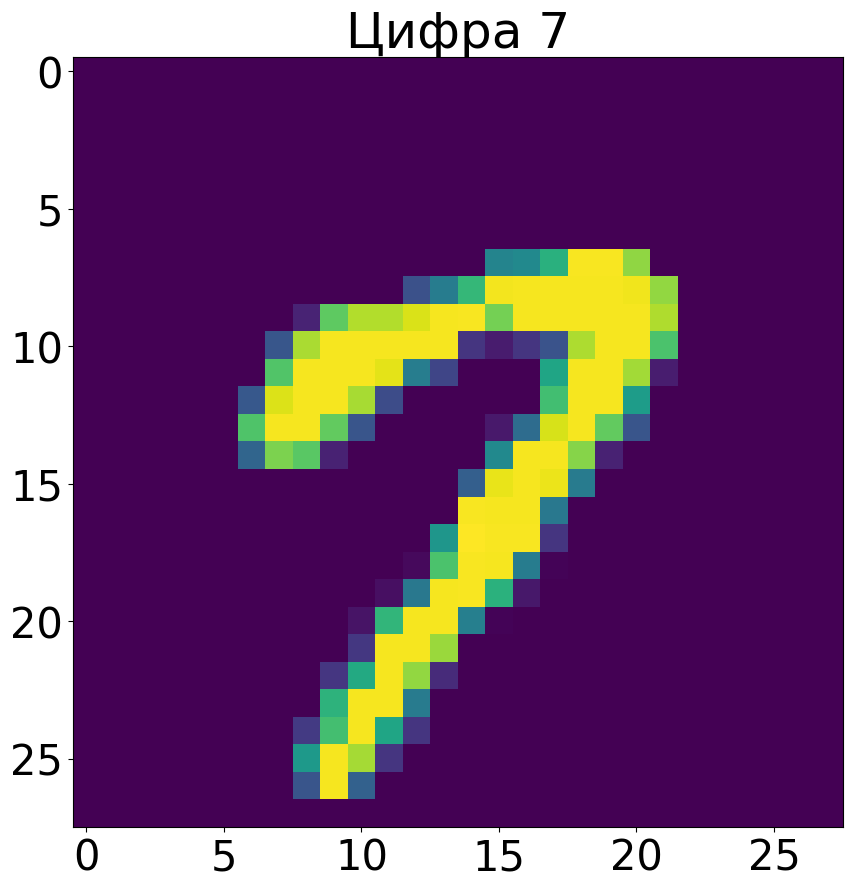

In [36]:
plt.figure(figsize=(10, 10))
# Получаем 15-й объект: изображение и метку.
# mnist_train[15][0] - это тензор изображения (1, 28, 28).
# [0] после тензора обращается к единственному каналу для отображения Matplotlib.
plt.title(f'Цифра {mnist_train[15][1]}') # Метка класса (например, 7)
plt.imshow(mnist_train[15][0][0]) # Само изображение

plt.show()

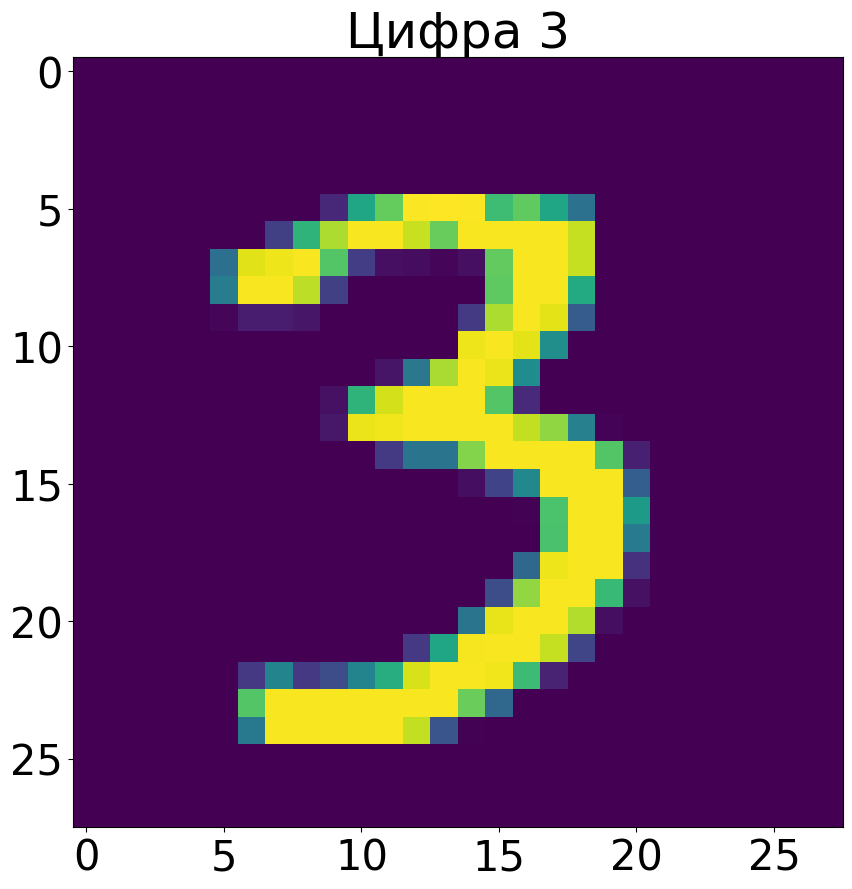

In [37]:
plt.figure(figsize=(10, 10))
plt.title(f'Цифра {mnist_train[10000][1]}')
plt.imshow(mnist_train[10000][0][0])

plt.show()

## Вспомогательные функции для обучения и оценки

Для удобства обучения и оценки моделей мы определим три вспомогательные функции:
1.  `train`: Выполняет один цикл обучения по всем батчам обучающей выборки, вычисляет ошибку и обновляет веса модели.
2.  `evaluate`: Оценивает модель на заданном даталоадере (обычно валидационном или тестовом), вычисляет среднюю ошибку и точность (accuracy).
3.  `plot_stats`: Визуализирует историю ошибки и точности на протяжении обучения.

Эти функции написаны таким образом, чтобы их можно было использовать для обучения различных моделей, что позволит нам легко сравнивать производительность полносвязной и сверточной сетей.

### Разбор функций:

#### `train(model: nn.Module) -> float:`
*   `model.train()`: Переводит модель в режим обучения. Это важно, так как некоторые слои (например, Dropout, BatchNorm) ведут себя по-разному в режимах обучения и оценки.
*   `optimizer.zero_grad()`: Обнуляет градиенты. В PyTorch градиенты накапливаются, поэтому их нужно обнулять перед каждым шагом оптимизации.
*   `output = model(x)`: Выполняет прямой проход (forward pass) модели, получая предсказания.
*   `loss = loss_fn(output, y)`: Вычисляет значение функции потерь между предсказаниями модели (`output`) и истинными метками (`y`).
*   `loss.item()`: Извлекает скалярное значение ошибки из тензора PyTorch.
*   `loss.backward()`: Выполняет обратный проход (backward pass), вычисляя градиенты функции потерь по отношению ко всем обучаемым параметрам модели.
*   `optimizer.step()`: Обновляет веса модели на основе вычисленных градиентов и алгоритма оптимизации (например, Adam).
*   `tqdm(train_loader, desc='Train')`: Использует библиотеку `tqdm` для отображения красивого прогресс-бара во время итерации по даталоадеру, что улучшает пользовательский опыт.

#### `@torch.inference_mode()`
Это декоратор, который оборачивает функцию `evaluate`. Он аналогичен использованию `with torch.no_grad():`. Его основное назначение:
*   **Отключение вычисления градиентов:** Во время оценки модели нам не нужно вычислять градиенты (поскольку веса не обновляются). Отключение этого процесса экономит память и ускоряет вычисления.
*   **`model.eval()`:** Переводит модель в режим оценки. Важно для слоев, таких как Dropout (отключается) или BatchNorm (использует зафиксированные статистики).

#### `evaluate(model: nn.Module, loader: DataLoader) -> tuple[float, float]:`
*   `_, y_pred = torch.max(output, 1)`: Для многоклассовой классификации, `output` обычно содержит "логиты" для каждого класса. `torch.max(output, 1)` находит максимальное значение (наибольший логит) по размерности `1` (размерности классов) и возвращает сам максимум, а также индекс этого максимума, который является предсказанным классом.
*   `total += y.size(0)`: Общее количество объектов в батче.
*   `correct += (y_pred == y).sum().item()`: Подсчитывает количество правильно классифицированных объектов, сравнивая предсказанные метки (`y_pred`) с истинными (`y`).
*   `accuracy = correct / total`: Вычисляет общую точность.

#### `plot_stats(...)`
*   Просто создает два графика с помощью `matplotlib`: один для потерь (train loss и valid loss), другой для точности (valid accuracy).
*   `clear_output()`: Очищает вывод предыдущей ячейки перед построением нового графика, чтобы на экране всегда отображался актуальный прогресс.

In [38]:
def train(model: nn.Module) -> float:
    # Переводим модель в режим обучения. Это активирует, например, Dropout и BatchNorm.
    model.train()

    train_loss = 0 # Инициализируем переменную для накопления общей ошибки на обучающей выборке.

    # Итерируемся по батчам данных из train_loader.
    # tqdm создает прогресс-бар для визуализации процесса.
    for x, y in tqdm(train_loader, desc='Train'):
        # Обнуляем градиенты оптимизатора перед каждым новым батчем,
        # чтобы они не накапливались от предыдущих итераций.
        optimizer.zero_grad()

        # Выполняем прямой проход: пропускаем входные данные 'x' через модель,
        # чтобы получить предсказания 'output'.
        output = model(x)

        # Вычисляем ошибку, сравнивая предсказания 'output' с истинными метками 'y'.
        loss = loss_fn(output, y)

        # Добавляем значение ошибки текущего батча к общей ошибке.
        train_loss += loss.item()

        # Выполняем обратный проход: вычисляем градиенты функции потерь по всем параметрам модели.
        loss.backward()

        # Делаем шаг оптимизации: обновляем веса модели на основе вычисленных градиентов.
        optimizer.step()

    # Усредняем общую ошибку по количеству батчей в даталоадере.
    train_loss /= len(train_loader)
    
    return train_loss # Возвращаем среднюю ошибку на обучающей выборке.

In [39]:
@torch.inference_mode() # Декоратор, который отключает вычисление градиентов, экономя память и ускоряя инференс.
def evaluate(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    # Переводим модель в режим оценки. Это отключает, например, Dropout и фиксирует BatchNorm.
    model.eval()

    total_loss = 0  # Инициализируем переменную для накопления общей ошибки.
    total = 0       # Инициализируем счетчик общего количества объектов.
    correct = 0     # Инициализируем счетчик правильно классифицированных объектов.

    # Итерируемся по батчам данных из заданного лоадера (например, valid_loader).
    for x, y in tqdm(loader, desc='Evaluation'):
        # Выполняем прямой проход, получаем предсказания модели.
        output = model(x)

        # Вычисляем ошибку.
        loss = loss_fn(output, y)

        # Добавляем ошибку текущего батча к общей ошибке.
        total_loss += loss.item()

        # Получаем предсказанные классы:
        # torch.max(output, 1) возвращает кортеж (максимальное_значение, индекс_максимального_значения).
        # Нам нужен индекс, который соответствует предсказанному классу. Размерность 1 - это классы.
        _, y_pred = torch.max(output, 1)
        
        # Обновляем общее количество объектов. y.size(0) - это размер батча.
        total += y.size(0)
        
        # Обновляем количество правильно классифицированных объектов.
        # (y_pred == y) создает булев тензор, .sum() считает True (1), .item() извлекает скаляр.
        correct += (y_pred == y).sum().item()

    # Усредняем общую ошибку.
    total_loss /= len(loader)
    # Вычисляем точность.
    accuracy = correct / total

    return total_loss, accuracy # Возвращаем среднюю ошибку и точность.

In [40]:
def plot_stats(
    train_loss: list[float],
    valid_loss: list[float],
    valid_accuracy: list[float],
    title: str
):
    # Создаем фигуру для графиков с заданным размером.
    plt.figure(figsize=(16, 8))

    # Устанавливаем заголовок для графика потерь.
    plt.title(title + ' loss')

    # Строим график ошибки на обучающей выборке.
    plt.plot(train_loss, label='Train loss')
    # Строим график ошибки на валидационной выборке.
    plt.plot(valid_loss, label='Valid loss')
    plt.legend() # Отображаем легенду.
    plt.grid()   # Отображаем сетку.

    plt.show() # Показываем график.

    plt.figure(figsize=(16, 8)) # Создаем новую фигуру для графика точности.

    # Устанавливаем заголовок для графика точности.
    plt.title(title + ' accuracy')

    # Строим график точности на валидационной выборке.
    plt.plot(valid_accuracy)
    plt.grid() # Отображаем сетку.

    plt.show() # Показываем график.

## Полносвязная нейронная сеть (Multilayer Perceptron, MLP)

Давайте сначала обучим на датасете MNIST обычную полносвязную нейронную сеть. Это позволит нам увидеть ограничения такого подхода для обработки изображений и затем наглядно сравнить его с эффективностью сверточных сетей.

**Архитектура MLP:**
1.  **`nn.Flatten()`:** Этот слой "разворачивает" входной тензор изображения из формата `(каналы, высота, ширина)` в одномерный вектор `(каналы * высота * ширина)`. Для MNIST изображения 1x28x28, это будет `1 * 28 * 28 = 784` элемента.
    *   **Недостаток:** Именно здесь теряется вся пространственная информация о взаимном расположении пикселей. Нейронная сеть "видит" изображение как длинный список чисел, а не как 2D-сетку.
2.  **`nn.Linear(28 * 28, 256)`:** Первый полносвязный слой. Он принимает на вход 784 значения (развернутое изображение) и проецирует их в 256-мерное пространство.
    *   **Много параметров:** Этот слой имеет `784 * 256 + 256 (bias) = 200,704` параметров.
3.  **`nn.ReLU()`:** Функция активации Rectified Linear Unit. Вводит нелинейность в модель, позволяя ей учиться более сложным зависимостям. `ReLU(x) = max(0, x)`.
4.  **`nn.Linear(256, 10)`:** Выходной полносвязный слой. Принимает 256 значений из предыдущего слоя и выдает 10 значений (по одному для каждого класса цифр от 0 до 9).
    *   **Количество параметров:** `256 * 10 + 10 (bias) = 2,570` параметров.
    *   Эти 10 выходных значений называются "логитами" и представляют собой "сырые" предсказания модели для каждого класса. Для получения вероятностей их обычно пропускают через Softmax (что `nn.CrossEntropyLoss` делает неявно).

**Итого:** Общее количество обучаемых параметров для этой MLP сети составит `200,704 + 2,570 = 203,274`. Для относительно простой задачи и такого маленького датасета это уже довольно много.

**Функция потерь (`loss_fn = nn.CrossEntropyLoss()`):**
Для многоклассовой классификации `nn.CrossEntropyLoss` является стандартным выбором. Эта функция **совмещает в себе Softmax и Negative Log Likelihood Loss**. То есть, модели не нужно явно применять Softmax на выходном слое; `CrossEntropyLoss` делает это за нее, принимая на вход "сырые" логиты.

**Оптимизатор (`optimizer = torch.optim.Adam(first_model.parameters(), lr=1e-3)`):**
**Adam (Adaptive Moment Estimation)** — популярный алгоритм оптимизации, который эффективно адаптирует скорость обучения (learning rate) для каждого параметра, что часто приводит к быстрой сходимости и хорошей производительности. `lr=1e-3` (0.001) — это начальная скорость обучения.

In [41]:
# Определяем архитектуру полносвязной нейронной сети (MLP).
first_model = nn.Sequential(
    nn.Flatten(),                     # Разворачивает входное изображение 1x28x28 в вектор 784.
    nn.Linear(28 * 28, 256),          # Первый полносвязный слой: 784 входа, 256 выходов.
    nn.ReLU(),                        # Функция активации ReLU.
    nn.Linear(256, 10)                # Второй полносвязный слой: 256 входов, 10 выходов (по количеству классов MNIST).
)

# Инициализируем оптимизатор Adam. Он будет отвечать за обновление весов модели.
optimizer = torch.optim.Adam(first_model.parameters(), lr=1e-3)

# Определяем функцию потерь. CrossEntropyLoss часто используется для многоклассовой классификации
# и включает в себя Softmax-активацию на выходе модели.
loss_fn = nn.CrossEntropyLoss()

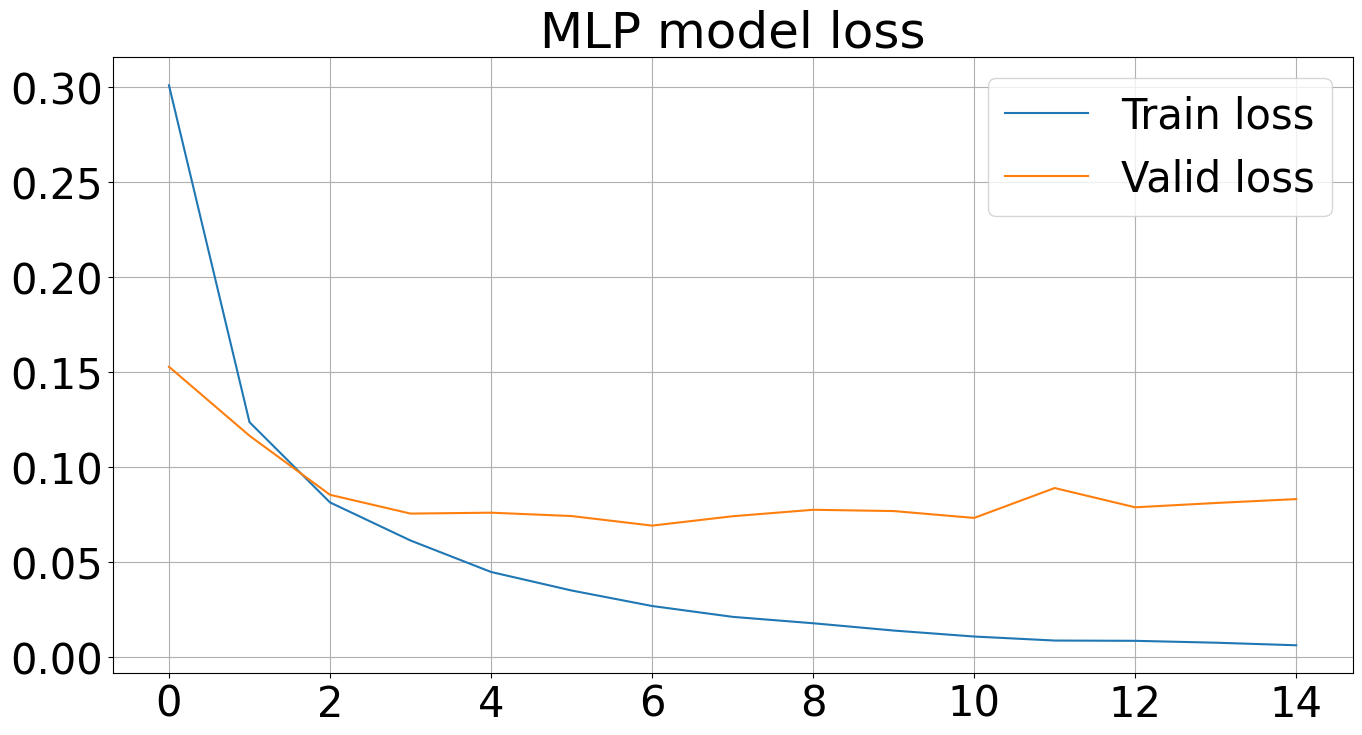

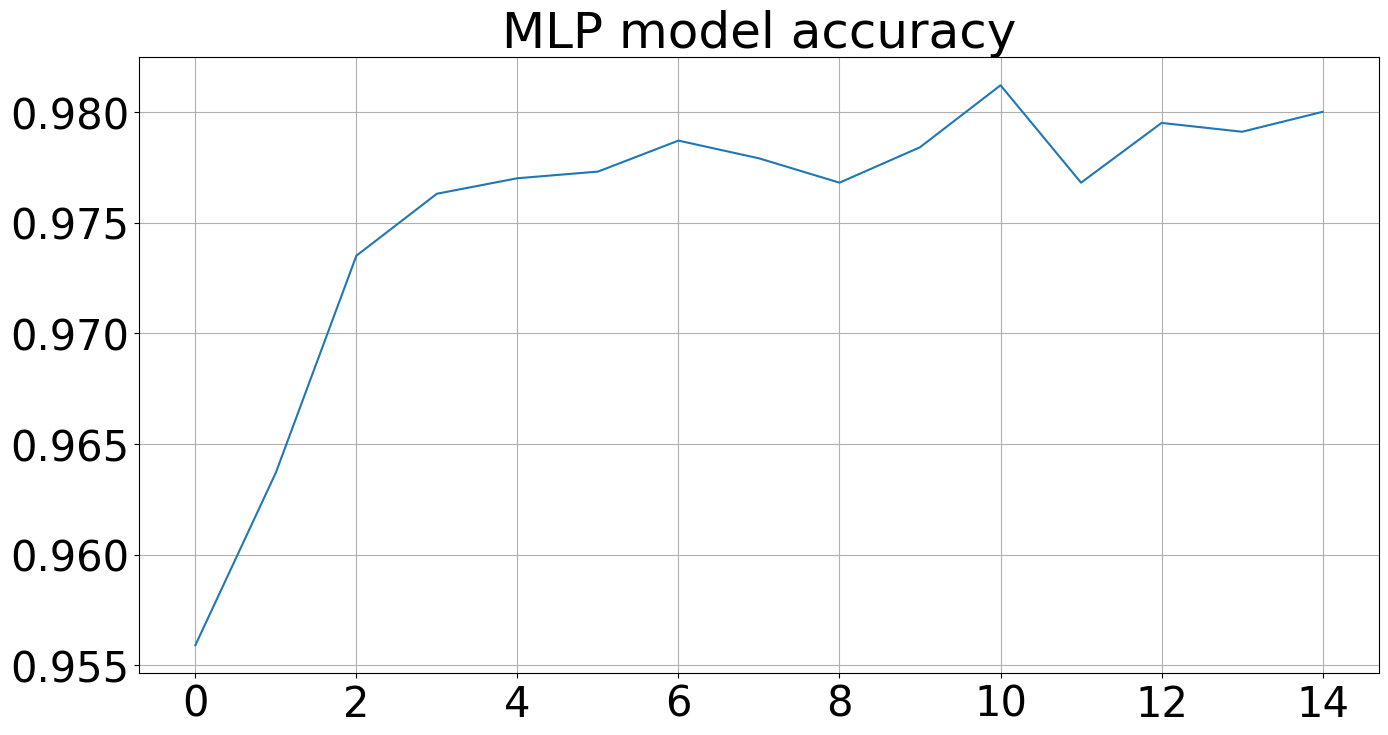

Total training and evaluation time 68.87794 seconds


In [42]:
num_epochs = 15 # Количество эпох обучения. Эпоха - это один полный проход по всей обучающей выборке.

train_loss_history, valid_loss_history = [], [] # Списки для хранения истории потерь на обучении и валидации.
valid_accuracy_history = []                     # Список для хранения истории точности на валидации.

start = perf_counter() # Записываем время начала обучения для измерения общей продолжительности.

for epoch in range(num_epochs): # Запускаем цикл обучения на заданное количество эпох.
    # Выполняем шаг обучения на обучающей выборке и получаем среднюю ошибку.
    train_loss = train(first_model)

    # Оцениваем модель на валидационной выборке, получаем среднюю ошибку и точность.
    valid_loss, valid_accuracy = evaluate(first_model, valid_loader)

    # Добавляем полученные значения в списки истории.
    train_loss_history.append(train_loss)
    valid_loss_history.append(valid_loss)
    valid_accuracy_history.append(valid_accuracy)
    
    clear_output() # Очищаем вывод текущей ячейки, чтобы графики обновлялись в реальном времени.

    # Строим графики потерь и точности.
    plot_stats(train_loss_history, valid_loss_history, valid_accuracy_history, 'MLP model')
    
# Выводим общее время, затраченное на обучение и оценку.
print(f'Total training and evaluation time {perf_counter() - start:.5f} seconds')

**Анализ результатов MLP на MNIST:**

После 15 эпох обучения полносвязная нейронная сеть достигает точности около 98% на валидационной выборке. Для новичка это может показаться хорошим результатом, но на самом деле для такого простого датасета, как MNIST, это довольно посредственный показатель.

**Наблюдения:**
*   **Переобучение:** Если внимательно посмотреть на графики потерь, можно заметить, что `Train loss` продолжает падать, в то время как `Valid loss` либо стагнирует, либо начинает немного расти после нескольких эпох. Это явный признак **переобучения** — модель слишком хорошо "запомнила" обучающую выборку, но плохо обобщает на новые, ранее не виденные данные.
*   **Ограничения:** В лекции упоминалось, что MLP-сети, несмотря на свой потенциал, имеют множество параметров и могут быть неинвариантны к сдвигам/поворотам объектов. Для MNIST, где цифры всегда центрированы и примерно одинакового размера, это не так критично, но на более сложных изображениях проблемы были бы очевидны. Чтобы достичь высоких показателей (например, 99.75%), полносвязная сеть потребует колоссального количества параметров (миллионы) и длительного обучения (десятки часов), как было показано в одном из научных исследований.

В целом, MLP может справиться с классификацией MNIST, но не является оптимальным решением. Она не использует пространственные корреляции между пикселями, что приводит к неэффективному использованию ресурсов и затрудняет обобщение. Теперь давайте посмотрим, как сверточные нейронные сети решают эти проблемы.

## Сверточная нейронная сеть (CNN)

Теперь мы построим и обучим сверточную нейронную сеть (CNN) для классификации тех же рукописных цифр MNIST. Мы увидим, как CNNs, благодаря использованию сверток и пулинга, достигают лучшего качества с меньшим количеством параметров и за меньшее время.

**Типичная архитектура CNN (пример):**
CNNs обычно состоят из чередующихся сверточных (`nn.Conv2d`), активационных (`nn.ReLU`) и пулинг-слоев (`nn.MaxPool2d`), за которыми следуют один или несколько полносвязных слоев (`nn.Linear`) для конечной классификации.

**Разберем архитектуру нашей CNN для MNIST:**

1.  **Первый сверточный блок:**
    *   `nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5)`:
        *   `in_channels=1`: Вход — одноканальное (grayscale) изображение MNIST.
        *   `out_channels=32`: Будем искать 32 различных признака/паттерна.
        *   `kernel_size=5`: Используем ядро 5x5.
        *   **Размер выхода:** Поскольку `padding` не указан (по умолчанию 0) и `stride=1`: `Высота_выхода = H_in - K + 1 = 28 - 5 + 1 = 24`. Аналогично для ширины.
        *   **Форма после Conv2d:** `(N, 32, 24, 24)`.
    *   `nn.ReLU()`: Функция активации после свертки.
    *   `nn.MaxPool2d(kernel_size=2)`:
        *   `kernel_size=2`: Окно пулинга 2x2.
        *   `stride` по умолчанию равен `kernel_size` (т.е., 2), что уменьшает размер вдвое.
        *   **Размер выхода:** `Высота_выхода = H_in / stride = 24 / 2 = 12`.
        *   **Форма после MaxPool2d:** `(N, 32, 12, 12)`.

2.  **Второй сверточный блок:**
    *   `nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5)`:
        *   `in_channels=32`: Количество каналов приходит от предыдущего слоя пулинга.
        *   `out_channels=64`: Ищем 64 более сложных признака.
        *   `kernel_size=5`.
        *   **Размер выхода:** `12 - 5 + 1 = 8`.
        *   **Форма после Conv2d:** `(N, 64, 8, 8)`.
    *   `nn.ReLU()`.
    *   `nn.MaxPool2d(kernel_size=2)`:
        *   **Размер выхода:** `8 / 2 = 4`.
        *   **Форма после MaxPool2d:** `(N, 64, 4, 4)`.

3.  **Полносвязные слои (Classifier Head):**
    *   `nn.Flatten()`: Теперь, когда сверточные слои извлекли и агрегировали пространственные признаки, нам нужно "развернуть" полученные 3D-карты признаков в одномерный вектор, чтобы подать их на вход полносвязному слою.
        *   **Размер выхода:** Из `(N, 64, 4, 4)` получим `(N, 64 * 4 * 4)`. `64 * 4 * 4 = 1024`.
    *   `nn.Linear(4 * 4 * 64, 256)`: Первый полносвязный слой, принимающий 1024 признака и проецирующий их в 256-мерное пространство.
    *   `nn.ReLU()`.
    *   `nn.Linear(256, 10)`: Выходной полносвязный слой для классификации на 10 классов.

**Поле восприятия (Receptive Field):**
Поле восприятия нейрона в сверточной сети — это размер области входного изображения, которая влияет на значение этого нейрона.
*   Для `kernel_size=3`, поле восприятия 3x3.
*   Для двух стеков `Conv(3x3) + Conv(3x3)`, поле восприятия становится 5x5.
*   Пулинг-слои, а также слои со страйдом (`stride > 1`) и дилейшном (`dilation > 1`) значительно увеличивают поле восприятия последующих слоев. Наша CNN с двумя блоками `Conv(5x5) + MaxPool(2x2)` позволяет выходным нейронам на последнем сверточном слое "видеть" значительную часть или даже все исходное изображение MNIST, что важно для принятия решения о классе.

Свертки обеспечивают локальную связность и общие веса, а пулинг уменьшает пространственные размеры и добавляет инвариантность к небольшим сдвигам. Эта комбинация делает CNNs чрезвычайно эффективными для задач компьютерного зрения.

In [43]:
# Определяем архитектуру сверточной нейронной сети (CNN).
second_model = nn.Sequential(
    # Первый сверточный блок
    nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5), # Вход: 1 канал (MNIST), 32 выходных канала, ядро 5x5.
                                                              # Размер выхода: (28-5+1) = 24. Тензор: (N, 32, 24, 24).
    nn.ReLU(),                                                # Функция активации ReLU.
    nn.MaxPool2d(kernel_size=2),                              # Макс-пулинг 2x2. Уменьшает размер в 2 раза.
                                                              # Размер выхода: 24/2 = 12. Тензор: (N, 32, 12, 12).

    # Второй сверточный блок
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5), # Вход: 32 канала (от предыдущего слоя), 64 выходных канала, ядро 5x5.
                                                              # Размер выхода: (12-5+1) = 8. Тензор: (N, 64, 8, 8).
    nn.ReLU(),                                                # Функция активации ReLU.
    nn.MaxPool2d(kernel_size=2),                              # Макс-пулинг 2x2. Уменьшает размер в 2 раза.
                                                              # Размер выхода: 8/2 = 4. Тензор: (N, 64, 4, 4).

    # Полносвязные слои для классификации
    nn.Flatten(),                                             # Разворачивает тензор (N, 64, 4, 4) в (N, 64*4*4=1024) вектор.
    nn.Linear(4 * 4 * 64, 256),                               # Первый полносвязный слой: 1024 входа, 256 выходов.
    nn.ReLU(),                                                # Функция активации ReLU.
    nn.Linear(256, 10)                                        # Второй полносвязный слой: 256 входов, 10 выходов (по числу классов).
)

# Инициализируем оптимизатор Adam.
optimizer = torch.optim.Adam(second_model.parameters(), lr=1e-3)

# Определяем функцию потерь CrossEntropyLoss.
loss_fn = nn.CrossEntropyLoss()

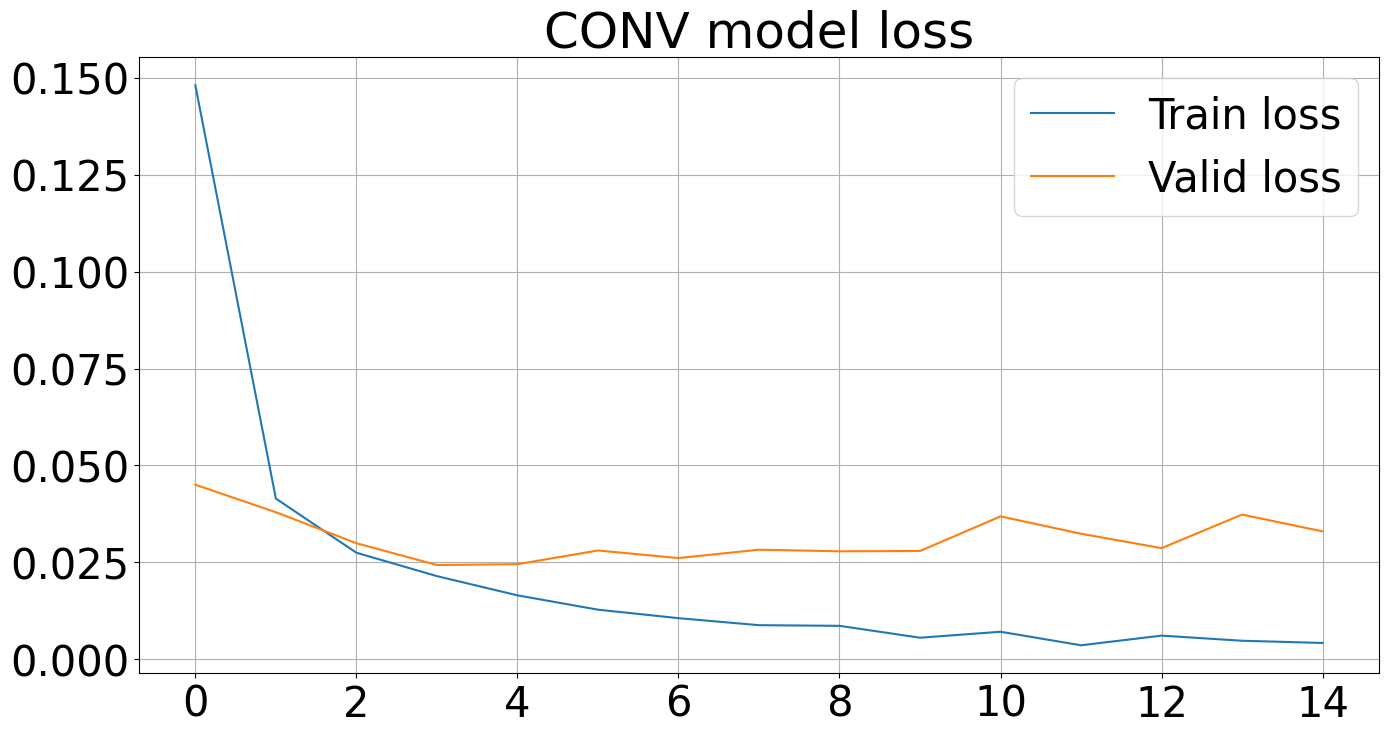

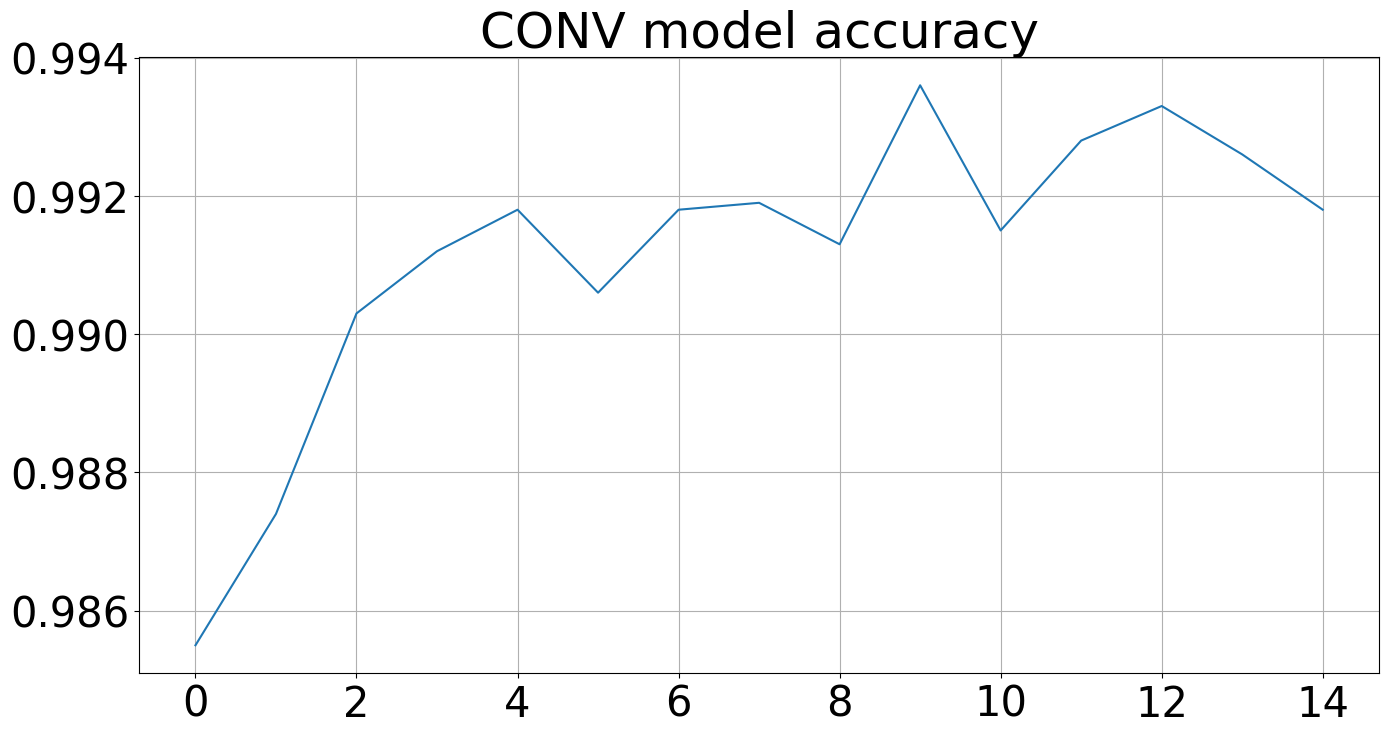

Total training and evaluation time 183.13161 seconds


In [44]:
num_epochs = 15 # Количество эпох обучения.

train_loss_history, valid_loss_history = [], [] # Списки для хранения истории потерь.
valid_accuracy_history = []                     # Список для хранения истории точности.

start = perf_counter() # Записываем время начала обучения.

for epoch in range(num_epochs): # Запускаем цикл обучения.
    # Обучаем модель на одной эпохе.
    train_loss = train(second_model)

    # Оцениваем модель на валидационной выборке.
    valid_loss, valid_accuracy = evaluate(second_model, valid_loader)

    # Сохраняем статистику.
    train_loss_history.append(train_loss)
    valid_loss_history.append(valid_loss)
    valid_accuracy_history.append(valid_accuracy)

    clear_output() # Очищаем вывод для обновления графиков.

    # Строим графики.
    plot_stats(train_loss_history, valid_loss_history, valid_accuracy_history, 'CONV model')

print(f'Total training and evaluation time {perf_counter() - start:.5f} seconds')

**Анализ результатов CNN на MNIST:**

Как мы видим, сверточная нейронная сеть достигает гораздо более высокого качества на валидационной выборке (~99.2%) за то же количество эпох и значительно быстрее, чем полносвязная сеть.

**Ключевые выводы:**
*   **Превосходство CNN:** Сверточные сети демонстрируют значительно лучшую производительность для задач классификации изображений. Это связано с их способностью эффективно извлекать пространственные признаки и использовать преимущества локальной связности и общих весов, что делает их более подходящими для визуальных данных.
*   **Эффективность параметров:** CNNs достигают лучших результатов с меньшим количеством параметров, чем MLP, благодаря использованию сверток и пулинга. Это снижает риск переобучения и ускоряет обучение.
*   **Инвариантность:** Хотя мы не тестировали это явно, архитектура CNN по своей природе более инвариантна к небольшим сдвигам и искажениям объектов на изображении благодаря свойствам сверток и пулинга.
*   **Продолжение обучения:** Несмотря на отличное качество, график `Valid loss` все еще может демонстрировать небольшое расхождение с `Train loss`, указывая на легкое переобучение. На следующих лекциях мы изучим дополнительные слои и техники (например, дропаут, батч-нормализацию), которые помогут еще лучше бороться с переобучением и улучшать обобщающую способность моделей.

Этот семинар показал фундаментальное преимущество сверточных нейронных сетей в области компьютерного зрения. Это лишь базовый пример, и современные архитектуры CNNs могут быть гораздо более сложными и глубокими, позволяя решать задачи на гораздо более сложных датасетах с впечатляющей точностью.